# Notebook 2 — terminal-gradient dimension × generative coupling

Three new tasks use one construction: independent_d2 (d=2, rho=0),
independent_d16 (d=16, rho=0), and coupled_d16 (d=16, rho=.5).
These are exploratory, fixed before formal execution. The previous
four-mode two-dimensional Flow experiment is retained as a historical
runnable notebook and is not used as the independent_d2 result.

We study a fixed true objective, J = path KL - beta E[R]. Oracle AM
replaces only the terminal gradient label; it is a diagnostic, not an
exact policy gradient or a deployable method. No gradient corruption,
guard, or new control algorithm is introduced.

Each seed trains its own Flow from behavior samples and five scalar
reward models from 512 noisy observations. Learned and oracle actors
start from the identical frozen Flow and use paired noise streams.

In [1]:
import copy
import hashlib
import json
import math
import os
import platform
import sys
import tempfile
import time
import traceback
from contextlib import contextmanager
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from torch import nn


ROOT = Path.cwd() if (Path.cwd()/'pyproject.toml').exists() else Path.cwd().parent
assert (ROOT/'pyproject.toml').exists(), 'Run from the repository or notebooks directory'
SPEC_PATH = ROOT/'configs/flow_am_dimension_coupling.json'


def configuration(profile='formal'):
    raw = json.loads(SPEC_PATH.read_text())
    c = SimpleNamespace(**raw)
    c.tasks = tuple(SimpleNamespace(**item) for item in raw['tasks'])
    c.seeds = tuple(raw['seeds'])
    c.actor_checkpoints = tuple(raw['actor_checkpoints'])
    c.diagnostic_checkpoints = tuple(raw['diagnostic_checkpoints'])
    c.adam_betas = tuple(raw['adam_betas'])
    c.profile = profile
    if profile == 'smoke':
        c.seeds = (raw['smoke_seed'],)
        c.behavior_train, c.behavior_valid, c.calibration_paths = 128, 64, 256
        c.reward_train, c.reward_valid = 64, 32
        c.fm_updates, c.reward_updates, c.actor_updates = 20, 20, 4
        c.fm_validate_every, c.reward_validate_every = 10, 10
        c.actor_checkpoints, c.diagnostic_checkpoints = (0, 2, 4), (0, 4)
        c.curve_every, c.curve_paths, c.final_paths = 2, 32, 64
        c.diagnostic_repeats, c.projection_directions = 2, 8
        c.steps, c.ode_steps = 8, 16
    elif profile != 'formal':
        raise ValueError(profile)
    return c


def config_dict(c):
    result = dict(vars(c))
    result['tasks'] = [dict(vars(task)) for task in c.tasks]
    for key in ('seeds', 'actor_checkpoints', 'diagnostic_checkpoints', 'adam_betas'):
        result[key] = list(result[key])
    return result


def generator(seed):
    return torch.Generator(device='cpu').manual_seed(int(seed))


def seed_key(task_index, seed, role):
    if not 0 <= role < 10000000:
        raise ValueError('RNG role outside reserved task-seed namespace')
    return (task_index+1)*1000000000000+int(seed)*10000000+int(role)


def ensure_finite(name, *values):
    for value in values:
        if not torch.isfinite(value).all():
            raise FloatingPointError(f'{name}: non-finite; no sample discarded')


def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False)+'\n')


def tensor_hash(value):
    return hashlib.sha256(value.detach().cpu().contiguous().numpy().tobytes()).hexdigest()


def model_hash(model):
    return hashlib.sha256(''.join(tensor_hash(t) for t in model.state_dict().values()).encode()).hexdigest()


def freeze(model):
    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)
        parameter.grad = None
    return model


def actor_copy(base):
    actor = copy.deepcopy(base)
    for parameter in actor.parameters():
        parameter.requires_grad_(True)
    return actor


def flat_parameters(model):
    return torch.nn.utils.parameters_to_vector(model.parameters()).detach().clone()


def flat_gradient(loss, model):
    return torch.cat([p.flatten() for p in torch.autograd.grad(loss, tuple(model.parameters()))]).detach()


def mean_se(x):
    x = x.detach().double()
    return float(x.mean()), float(x.std(unbiased=True)/math.sqrt(len(x)))


def cosine(a, b):
    a, b = a.double().flatten(), b.double().flatten()
    size = float(a.norm()*b.norm())
    return float(a@b/size) if size > 1e-20 else None


torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
CFG = configuration(os.environ.get('PAGR_DIM_PROFILE', 'formal'))
(ROOT/'runs').mkdir(exist_ok=True)
OUT = Path(tempfile.mkdtemp(prefix=f'02-flow-am-dim-{CFG.profile}-', dir=ROOT/'runs'))
CONFIG_SHA = hashlib.sha256(SPEC_PATH.read_bytes()).hexdigest()
SOURCE_SHA = hashlib.sha256((ROOT/'notebooks/02_flow_am_dimension_coupling.py').read_bytes()).hexdigest()
save_json(OUT/'config.json', config_dict(CFG))
save_json(OUT/'environment.json', dict(python=sys.version, torch=torch.__version__,
          numpy=np.__version__, pandas=pd.__version__, platform=platform.platform(),
          threads=torch.get_num_threads(), device='cpu', source_sha256=SOURCE_SHA,
          formal_spec_sha256=CONFIG_SHA))
print('New run:', OUT.relative_to(ROOT))
display(pd.DataFrame([dict(vars(task)) for task in CFG.tasks]))

New run: runs/02-flow-am-dim-formal-8q5obfng


,name,dim,rho
0,independent_d2,2,0.0
1,independent_d16,16,0.0
2,coupled_d16,16,0.5


## 1. Behavior, reward, and scalar-observation protocol

Draw z~N(0,I_d); set a_1=z_1 and a_j=z_j+rho sin(z_{j-1})
for j=2,...,d. The right side uses the previous z coordinate.
At rho=0, coordinates are independent. At rho=.5, neighboring
action coordinates have nonlinear statistical dependence.
The inverse is z_1=a_1, z_j=a_j-rho sin(z_{j-1}).

Every coordinate matters to the fixed true reward:
R_d(a)=-1/2 sum_j w_j(a_j-a*_j)^2, where a* alternates +1,-1
and w alternates .5,2. Its true gradient is -w(a-a*).
The observed labels are scalar R_d(a)+N(0,sigma_obs,d^2).
sigma_obs,d=.2 Std_behavior[R_d], estimated once using 16384
independent calibration actions. This is a data-generation rule.

Reward models train on 512 scalar observations and use only those
training labels to standardize targets. Their forward() returns raw
reward units; input autograd includes the inverse scaling.
Selection uses noisy validation MSE, never true gradients or actor J.

In [2]:
class Velocity(nn.Module):
    def __init__(self, dim, width):
        super().__init__()
        self.dim = dim
        self.net = nn.Sequential(nn.Linear(dim+3, width), nn.SiLU(),
                                 nn.Linear(width, width), nn.SiLU(),
                                 nn.Linear(width, dim))

    def features(self, x, t):
        t = torch.as_tensor(t, dtype=x.dtype, device=x.device).expand(*x.shape[:-1], 1)
        return torch.cat((x, t, torch.sin(math.pi*t), torch.cos(math.pi*t)), -1)

    def forward(self, x, t):
        return self.net(self.features(x, t))

    def input_vjp_cache(self, x, t):
        features = self.features(x, t)
        pre1 = self.net[0](features)
        pre2 = self.net[2](F.silu(pre1))
        return pre1, pre2

    def input_vjp_from_cache(self, pre1, pre2, vector):
        # Exact MLP input VJP, batched over paths; no d×d Jacobian allocation.
        def silu_prime(z):
            sigmoid = torch.sigmoid(z)
            return sigmoid*(1+z*(1-sigmoid))
        answer = (vector@self.net[4].weight)*silu_prime(pre2)
        answer = (answer@self.net[2].weight)*silu_prime(pre1)
        return (answer@self.net[0].weight)[..., :self.dim]

    def input_vjp(self, x, t, vector):
        return self.input_vjp_from_cache(*self.input_vjp_cache(x, t), vector)


class RewardModel(nn.Module):
    def __init__(self, dim, width):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, width), nn.SiLU(),
                                 nn.Linear(width, width), nn.SiLU(),
                                 nn.Linear(width, 1))
        self.register_buffer('label_mean', torch.tensor(0.))
        self.register_buffer('label_std', torch.tensor(1.))

    def normalized(self, x):
        return self.net(x).squeeze(-1)

    def forward(self, x):
        return self.label_mean+self.label_std*self.normalized(x)


def behavior_transform(z, rho):
    answer = z.clone()
    answer[..., 1:] = z[..., 1:]+rho*torch.sin(z[..., :-1])
    return answer


def behavior_inverse(actions, rho):
    z = actions.clone()
    for j in range(1, actions.shape[-1]):
        z[..., j] = actions[..., j]-rho*torch.sin(z[..., j-1])
    return z


def behavior_sample(task, n, seed):
    return behavior_transform(torch.randn(n, task.dim, generator=generator(seed)), task.rho)


def reward_vectors(dim, reference):
    index = torch.arange(dim, device=reference.device)
    ones = torch.ones(dim, dtype=reference.dtype, device=reference.device)
    target = torch.where(index.remainder(2).eq(0), ones, -ones)
    weights = torch.where(index.remainder(2).eq(0), .5*ones, 2*ones)
    return target, weights


def true_reward(actions):
    target, weights = reward_vectors(actions.shape[-1], actions)
    return -.5*(weights*(actions-target).square()).sum(-1)


def true_gradient(actions):
    target, weights = reward_vectors(actions.shape[-1], actions)
    return -weights*(actions-target)


def scalar_gradient(fn, x):
    with torch.enable_grad():
        y = x.detach().requires_grad_(True)
        gradient = torch.autograd.grad(fn(y).sum(), y)[0]
    ensure_finite('scalar gradient', gradient)
    return gradient.detach()


@contextmanager
def forbid_truth():
    saved = {key: globals()[key] for key in ('true_reward', 'true_gradient')}
    def forbidden(*args, **kwargs):
        raise AssertionError('learned actor update accessed true reward or gradient')
    globals().update({key: forbidden for key in saved})
    try:
        yield
    finally:
        globals().update(saved)


def make_data(c, task, task_index, seed):
    role = lambda offset: seed_key(task_index, seed, offset)
    calibration = behavior_sample(task, c.calibration_paths, role(16))
    calibration_std = float(true_reward(calibration).std(unbiased=False))
    if calibration_std <= 1e-10:
        raise AssertionError('Degenerate calibration reward')
    sigma = c.observation_scale_fraction*calibration_std
    data = dict(behavior=behavior_sample(task, c.behavior_train, role(10)),
                heldout=behavior_sample(task, c.behavior_valid, role(11)),
                reward_x=behavior_sample(task, c.reward_train, role(12)),
                valid_x=behavior_sample(task, c.reward_valid, role(13)))
    data['reward_y'] = true_reward(data['reward_x'])+sigma*torch.randn(
        c.reward_train, generator=generator(role(14)))
    data['valid_y'] = true_reward(data['valid_x'])+sigma*torch.randn(
        c.reward_valid, generator=generator(role(15)))
    return data, dict(calibration_seed=role(16), calibration_paths=c.calibration_paths,
                      calibration_reward_std=calibration_std, observation_std=sigma,
                      observed_train_mean=float(data['reward_y'].mean()),
                      observed_train_std=float(data['reward_y'].std(unbiased=False)))


def fm_examples(actions, n, gen):
    dim = actions.shape[-1]
    a = actions[torch.randint(len(actions), (n,), generator=gen)]
    z, t = torch.randn(n, dim, generator=gen), torch.rand(n, 1, generator=gen)
    return (1-t)*z+t*a, t, a-z


def fit_base(c, task, data, task_index, seed):
    torch.manual_seed(seed_key(task_index, seed, 20))
    model = Velocity(task.dim, c.width)
    optimizer = torch.optim.Adam(model.parameters(), lr=c.fm_lr)
    gen = generator(seed_key(task_index, seed, 21))
    xv, tv, yv = fm_examples(data['heldout'], c.behavior_valid,
                              generator(seed_key(task_index, seed, 22)))
    history, best, chosen, state = [], float('inf'), -1, None
    for step in range(c.fm_updates+1):
        if step % c.fm_validate_every == 0 or step == c.fm_updates:
            with torch.no_grad():
                valid = float((model(xv, tv)-yv).square().sum(-1).mean()/task.dim)
            if not math.isfinite(valid):
                raise FloatingPointError('FM validation')
            history.append(dict(stage='fm', member=-1, update=step, heldout_loss_per_dim=valid))
            if valid < best:
                best, chosen, state = valid, step, copy.deepcopy(model.state_dict())
        if step == c.fm_updates:
            break
        x, t, target = fm_examples(data['behavior'], c.fm_batch, gen)
        loss = (model(x, t)-target).square().sum(-1).mean()/task.dim
        ensure_finite('FM loss', loss)
        optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
    model.load_state_dict(state)
    return freeze(model), history, dict(selected_update=chosen, heldout_loss_per_dim=best)


def fit_rewards(c, task, data, task_index, seed):
    mean = data['reward_y'].mean().detach()
    scale = data['reward_y'].std(unbiased=False).detach()
    if scale < 1e-10:
        raise AssertionError('Degenerate reward training labels')
    models, histories, selections = [], [], []
    for member in range(c.ensemble_members):
        torch.manual_seed(seed_key(task_index, seed, 100+member))
        model = RewardModel(task.dim, c.width)
        model.label_mean.copy_(mean)
        model.label_std.copy_(scale)
        optimizer = torch.optim.Adam(model.parameters(), lr=c.reward_lr)
        gen = generator(seed_key(task_index, seed, 200+member))
        index = torch.randint(c.reward_train, (c.reward_train,), generator=gen)
        x, y = data['reward_x'][index], (data['reward_y'][index]-mean)/scale
        best, chosen, state = float('inf'), -1, None
        for step in range(c.reward_updates+1):
            if step % c.reward_validate_every == 0 or step == c.reward_updates:
                with torch.no_grad():
                    valid = float((model(data['valid_x'])-data['valid_y']).square().mean())
                if not math.isfinite(valid):
                    raise FloatingPointError('reward validation')
                histories.append(dict(stage='reward', member=member, update=step, noisy_valid_mse=valid))
                if valid < best:
                    best, chosen, state = valid, step, copy.deepcopy(model.state_dict())
            if step == c.reward_updates:
                break
            batch = torch.randint(len(x), (c.reward_batch,), generator=gen)
            loss = (model.normalized(x[batch])-y[batch]).square().mean()
            ensure_finite('reward training loss', loss)
            optimizer.zero_grad(set_to_none=True); loss.backward(); optimizer.step()
        model.load_state_dict(state)
        models.append(freeze(model))
        selections.append(dict(member=member, selected_update=chosen, noisy_valid_mse=best,
                               label_mean=float(mean), label_std=float(scale)))
    return models, histories, selections


def reward_mean(models, x):
    return torch.stack([model(x) for model in models]).mean(0)


def terminal_label(models, endpoint, c, source):
    if source == 'oracle':
        gradient = true_gradient(endpoint)
    elif source == 'learned':
        gradient = scalar_gradient(lambda x: reward_mean(models, x), endpoint)
    else:
        raise ValueError(source)
    return -c.beta*gradient

## 2. Finite diffusion, lean adjoint, and dimension-normalized matching

The generation direction is noise→action, x_t=(1-t)z+ta.
FM learns v_base by minimizing E||v_base(x_t,t)-(a-z)||²/d.
It is trained from data; no drift is inserted by hand.

After a shared frozen-base RK2 warmup to epsilon=.05, the K=64
Euler–Maruyama steps use t_k=epsilon+kh, h=(1-epsilon)/K,
nu_k²=2(1-t_k)/t_k and b_theta=2v_theta-x/t_k.
The last step remains Gaussian. Terminal labels are taken at X_K:
p_K=-beta grad R_hat(X_K) or -beta grad R(X_K).

Lean backward uses p_k=p_{k+1}+h[D_x b_base(X_k,t_k)]^T p_{k+1}.
The frozen base MLP input VJP is computed directly from its layers,
without materializing a d×d Jacobian. Tests compare it with autograd.
Base parameters stay frozen while input differentiation remains valid.

Local matching on detached paths pairs X_k with p_{k+1}:
L_AM=h/(2Bd) sum_(i,k)||u_theta(X_k,t_k)+nu_k p_{k+1}||²,
u_theta=2(v_theta-v_base)/nu_k. The whole loss is divided by d.
There is no extra energy term and no actor state backpropagation.

The actual finite-chain KL is E sum_k h||u_k||²/2 because the
actor/base transition Gaussians share covariance h nu_k² I.
The reported objective is J=path KL-beta E[R], with per-dimension
summaries J/d, E[R]/d, and path KL/d. Dividing all reported terms
by d does not change beta.

In [3]:
def grid(c, dtype=torch.float32):
    h = (1-c.epsilon)/c.steps
    times = c.epsilon+h*torch.arange(c.steps, dtype=dtype)
    return times, torch.sqrt(2*(1-times)/times), h


def noise(c, dim, n, seed):
    # Fixed 64-path blocks preserve literal prefixes across batch sizes.
    blocks = math.ceil(n/64)
    initial, brownian = generator(seed), generator(seed+1)
    z = torch.cat([torch.randn(64, dim, generator=initial) for _ in range(blocks)])[:n]
    xi = torch.cat([torch.randn(64, c.steps, dim, generator=brownian)
                    for _ in range(blocks)])[:n]
    return z, xi


@torch.no_grad()
def ode_sample(model, z, steps, start=0., end=1.):
    x, h = z.detach().clone(), (end-start)/steps
    for k in range(steps):
        t = start+k*h
        midpoint = x+.5*h*model(x, t)
        x = x+h*model(midpoint, t+.5*h)
    ensure_finite('ODE sample', x)
    return x


@torch.no_grad()
def rollout(actor, base, c, z, xi):
    if z.shape[-1] != actor.dim or xi.shape != (len(z), c.steps, actor.dim):
        raise ValueError('d-dimensional rollout shapes')
    times, nu, h = grid(c, z.dtype)
    x = ode_sample(base, z, c.warmup_steps, end=c.epsilon)
    states, controls = [x], []
    for k in range(c.steps):
        velocity, base_velocity = actor(x, times[k]), base(x, times[k])
        controls.append(2*(velocity-base_velocity)/nu[k])
        x = x+h*(2*velocity-x/times[k])+math.sqrt(h)*nu[k]*xi[:, k]
        states.append(x)
    paths, control = torch.stack(states, 1).detach(), torch.stack(controls, 1).detach()
    ensure_finite('SDE rollout', paths, control)
    return paths, control


@torch.no_grad()
def lean_adjoint(paths, base, c, terminal):
    times, _, h = grid(c, paths.dtype)
    pre1, pre2 = base.input_vjp_cache(paths[:, :-1], times[None, :, None])
    p, sequence = terminal.detach(), [terminal.detach()]
    for k in range(c.steps-1, -1, -1):
        vjp = base.input_vjp_from_cache(pre1[:, k], pre2[:, k], p)
        p = p+h*(2*vjp-p/times[k])
        sequence.append(p)
    result = torch.stack(sequence[::-1], 1).detach()
    ensure_finite('lean adjoint', result)
    return result


def matching_loss(actor, base, paths, labels, c):
    x = paths[:, :-1].detach()
    times, nu, h = grid(c, x.dtype)
    t = times[None, :, None].expand(len(x), -1, 1)
    with torch.no_grad():
        vb = base(x, t)
    control = 2*(actor(x, t)-vb)/nu[None, :, None]
    residual = control+nu[None, :, None]*labels[:, 1:].detach()
    return .5*h*residual.square().sum((-1, -2)).mean()/actor.dim


def adam_for(actor, c):
    return torch.optim.Adam(actor.parameters(), lr=c.actor_lr, betas=c.adam_betas, eps=c.adam_eps)


def apply_gradient(actor, optimizer, gradient, c):
    ensure_finite('actor parameter gradient', gradient)
    optimizer.zero_grad(set_to_none=True)
    cursor = 0
    for parameter in actor.parameters():
        parameter.grad = gradient[cursor:cursor+parameter.numel()].reshape_as(parameter).clone()
        cursor += parameter.numel()
    torch.nn.utils.clip_grad_norm_(actor.parameters(), c.clip, error_if_nonfinite=True)
    clipped = torch.cat([p.grad.flatten() for p in actor.parameters()]).detach().clone()
    optimizer.step()
    ensure_finite('updated actor', flat_parameters(actor))
    return clipped


def actor_update(actor, optimizer, base, models, c, z, xi, source):
    paths, _ = rollout(actor, base, c, z, xi)
    labels = lean_adjoint(paths, base, c, terminal_label(models, paths[:, -1], c, source))
    loss = matching_loss(actor, base, paths, labels, c)
    raw = flat_gradient(loss, actor)
    clipped = apply_gradient(actor, optimizer, raw, c)
    return dict(loss=float(loss.detach()), raw_gradient_norm=float(raw.norm()),
                clipped_gradient_norm=float(clipped.norm()),
                clipping_triggered=bool(float(raw.norm()) > c.clip+1e-7))


@torch.no_grad()
def evaluate(actor, base, c, z, xi):
    paths, control = rollout(actor, base, c, z, xi)
    times, nu, h = grid(c)
    energy = .5*h*control.square().sum((-1, -2))
    x = paths[:, :-1]
    t = times[None, :, None].expand(len(x), -1, 1)
    mean_actor = x+h*(2*actor(x, t)-x/t)
    mean_base = x+h*(2*base(x, t)-x/t)
    conditional_kl = ((mean_actor-mean_base).square().sum(-1)/
                      (2*h*nu.square())).sum(-1)
    residual = float((energy-conditional_kl).abs().max())
    if not torch.allclose(energy, conditional_kl, atol=2e-5, rtol=2e-5):
        raise AssertionError('finite Gaussian-chain KL is not control energy')
    reward = true_reward(paths[:, -1])
    cost = energy-c.beta*reward
    result = dict(kl_identity_max_abs=residual)
    for name, values in [('reward', reward), ('energy', energy), ('cost', cost)]:
        result[name], result[name+'_mc_se'] = mean_se(values)
        result[name+'_per_dim'] = result[name]/actor.dim
    return result, dict(terminal=paths[:, -1], reward=reward, energy=energy,
                        cost=cost, paths=paths)

## 3. Pretraining quality and fixed-budget actor runs

Behavior, Base ODE, and Base SDE are compared by per-coordinate mean,
variance, neighboring correlation, and a fixed random-projection W2.
The projection score is an empirical distance, not a KL estimate or
proof of high-dimensional fit. For coupled behavior, the known
triangular inverse also checks mapped-back Gaussian moments.

Learned and Oracle use the same data, Base, reward ensemble, initial
actor parameters, Adam initialization, 300 updates and B64 noises.
Once their actors diverge, their state paths are no longer identical.
Both use the fixed final update; no true reward selects a checkpoint.

In [4]:
def adjacent_correlations(x):
    centered = x.double()-x.double().mean(0)
    variance = centered.square().mean(0).clamp_min(1e-12)
    covariance = (centered[:, :-1]*centered[:, 1:]).mean(0)
    return (covariance/torch.sqrt(variance[:-1]*variance[1:])).float()


def distribution_summary(x):
    mean = x.mean(0)
    variance = x.var(0, unbiased=False)
    adjacent = adjacent_correlations(x)
    return dict(mean=mean.numpy().tolist(), variance=variance.numpy().tolist(),
                adjacent_correlation=adjacent.numpy().tolist(),
                mean_abs_mean=float(mean.abs().mean()),
                mean_variance=float(variance.mean()),
                mean_abs_adjacent_correlation=float(adjacent.abs().mean()))


def projection_distance(x, y, seed, directions):
    if x.shape != y.shape:
        raise ValueError('projection distance requires paired sample counts and dimension')
    dim = x.shape[-1]
    direction = torch.randn(directions, dim, generator=generator(seed))
    direction = direction/direction.norm(dim=-1, keepdim=True)
    left, right = (x@direction.T).sort(0).values, (y@direction.T).sort(0).values
    return float((left-right).square().mean().sqrt())


def base_quality(c, task, task_index, seed, base, data):
    n = min(c.behavior_valid, c.final_paths)
    behavior = data['heldout'][:n]
    z, xi = noise(c, task.dim, n, seed_key(task_index, seed, 900000))
    ode = ode_sample(base, z, c.ode_steps)
    sde = rollout(base, base, c, z, xi)[0][:, -1]
    directions = seed_key(task_index, seed, 900004)
    quality = dict(task=task.name, seed=seed, dim=task.dim, rho=task.rho,
                   behavior=distribution_summary(behavior),
                   base_ode=distribution_summary(ode),
                   base_sde=distribution_summary(sde),
                   ode_random_projection_w2=projection_distance(
                       behavior, ode, directions, c.projection_directions),
                   sde_random_projection_w2=projection_distance(
                       behavior, sde, directions, c.projection_directions))
    for name, sample in [('ode', ode), ('sde', sde)]:
        gap = sample.mean(0)-behavior.mean(0)
        variance_gap = sample.var(0, unbiased=False)-behavior.var(0, unbiased=False)
        correlation_gap = adjacent_correlations(sample)-adjacent_correlations(behavior)
        inverse = behavior_inverse(sample, task.rho)
        quality[name+'_mean_gap_rms'] = float(gap.square().mean().sqrt())
        quality[name+'_variance_gap_rms'] = float(variance_gap.square().mean().sqrt())
        quality[name+'_adjacent_corr_gap_rms'] = float(correlation_gap.square().mean().sqrt())
        quality[name+'_inverse_z_mean_rms'] = float(inverse.mean(0).square().mean().sqrt())
        quality[name+'_inverse_z_variance_gap_rms'] = float(
            (inverse.var(0, unbiased=False)-1).square().mean().sqrt())
    return quality, dict(behavior=behavior, ode=ode, sde=sde)


def exact_tree_equal(a, b):
    if isinstance(a, torch.Tensor):
        return isinstance(b, torch.Tensor) and torch.equal(a, b)
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(
            exact_tree_equal(a[key], b[key]) for key in a)
    if isinstance(a, (tuple, list)):
        return type(a) is type(b) and len(a) == len(b) and all(
            exact_tree_equal(x, y) for x, y in zip(a, b))
    return a == b


def virtual_adam_steps(actor, optimizer, q_learned, q_oracle, c):
    parameters_before = flat_parameters(actor)
    optimizer_before = copy.deepcopy(optimizer.state_dict())
    rng_before = torch.get_rng_state().clone()
    steps = []
    for q in (q_learned, q_oracle):
        clone = copy.deepcopy(actor)
        clone_opt = adam_for(clone, c)
        clone_opt.load_state_dict(copy.deepcopy(optimizer_before))
        before = flat_parameters(clone)
        apply_gradient(clone, clone_opt, q, c)
        steps.append(flat_parameters(clone)-before)
    if not torch.equal(parameters_before, flat_parameters(actor)):
        raise AssertionError('virtual update changed formal actor')
    if not exact_tree_equal(optimizer_before, optimizer.state_dict()):
        raise AssertionError('virtual update changed formal optimizer')
    if not torch.equal(rng_before, torch.get_rng_state()):
        raise AssertionError('virtual update changed global training RNG')
    oracle_norm = float(steps[1].norm())
    return dict(step_cosine=cosine(*steps),
                step_norm_learned=float(steps[0].norm()),
                step_norm_oracle=oracle_norm,
                step_norm_ratio=float(steps[0].norm()/steps[1].norm())
                if oracle_norm > 1e-12 else None,
                step_relative_difference=float((steps[0]-steps[1]).norm()/steps[1].norm())
                if oracle_norm > 1e-12 else None)


@torch.no_grad()
def propagation_structure(base, c, paths):
    times, _, h = grid(c)
    eye = torch.eye(base.dim)
    rows = []
    for path_index in range(min(2, len(paths))):
        product = eye.clone()
        jacobians = []
        for k in range(c.steps-1, -1, -1):
            x = paths[path_index:path_index+1, k]
            time_k = times[k]
            basis = eye
            jac = torch.stack([
                base.input_vjp(x, time_k, basis[j:j+1])[0] for j in range(base.dim)
            ])
            jacobians.append(jac)
            f = eye+h*(2*jac-eye/time_k)
            product = f.T@product
        jacobians = torch.stack(jacobians)
        diagonal = torch.diag_embed(torch.diagonal(jacobians, dim1=-2, dim2=-1))
        offdiag = jacobians-diagonal
        singular = torch.linalg.svdvals(product)
        rows.append(dict(path_index=path_index,
                         base_jacobian_offdiag_fraction=float(
                             offdiag.square().sum().sqrt()/jacobians.square().sum().sqrt().clamp_min(1e-12)),
                         propagator_sigma_max=float(singular.max()),
                         propagator_sigma_min=float(singular.min()),
                         propagator_frobenius=float(product.norm())))
    return rows


def diagnostic_pair(actor, optimizer, base, models, c, task, task_index, seed, step, directory):
    rows, time_rows, structure_rows = [], [], []
    for repetition in range(c.diagnostic_repeats):
        role = 500000+step*1000+2*repetition
        z, xi = noise(c, task.dim, c.diagnostic_batch, seed_key(task_index, seed, role))
        paths, _ = rollout(actor, base, c, z, xi)
        endpoint = paths[:, -1]
        true_values, learned_values = true_reward(endpoint), reward_mean(models, endpoint)
        true_grad, learned_grad = true_gradient(endpoint), scalar_gradient(
            lambda x: reward_mean(models, x), endpoint)
        p_learned = lean_adjoint(paths, base, c, -c.beta*learned_grad)
        p_oracle = lean_adjoint(paths, base, c, -c.beta*true_grad)
        q_learned = flat_gradient(matching_loss(actor, base, paths, p_learned, c), actor)
        q_oracle = flat_gradient(matching_loss(actor, base, paths, p_oracle, c), actor)
        value_scale = float(true_values.std(unbiased=False))
        gradient_scale = float(true_grad.square().sum(-1).mean().sqrt())
        value_rmse = float((learned_values-true_values).square().mean().sqrt())
        gradient_rmse = float((learned_grad-true_grad).square().sum(-1).mean().sqrt())
        cosines = [cosine(a, b) for a, b in zip(learned_grad, true_grad)]
        valid_cosines = [value for value in cosines if value is not None]
        q_oracle_norm = float(q_oracle.norm())
        row = dict(task=task.name, seed=seed, dim=task.dim, rho=task.rho,
                   checkpoint_step=step, repetition=repetition,
                   noise_seed=seed_key(task_index, seed, role),
                   value_rmse=value_rmse,
                   value_rmse_over_true_reward_std=value_rmse/value_scale
                   if value_scale > 1e-12 else None,
                   reward_scale_undefined=value_scale <= 1e-12,
                   terminal_gradient_rmse=gradient_rmse,
                   terminal_gradient_relative_rms=gradient_rmse/gradient_scale
                   if gradient_scale > 1e-12 else None,
                   terminal_gradient_scale_undefined=gradient_scale <= 1e-12,
                   terminal_gradient_cosine_mean=float(np.mean(valid_cosines))
                   if valid_cosines else None,
                   terminal_gradient_cosine_undefined=len(cosines)-len(valid_cosines),
                   q_learned_norm=float(q_learned.norm()),
                   q_oracle_norm=q_oracle_norm,
                   q_cosine=cosine(q_learned, q_oracle),
                   q_norm_ratio=float(q_learned.norm()/q_oracle.norm())
                   if q_oracle_norm > 1e-12 else None,
                   q_relative_difference=float((q_learned-q_oracle).norm()/q_oracle.norm())
                   if q_oracle_norm > 1e-12 else None,
                   q_scale_undefined=q_oracle_norm <= 1e-12,
                   **virtual_adam_steps(actor, optimizer, q_learned, q_oracle, c))
        rows.append(row)
        for index in (0, c.steps//2, c.steps-1, c.steps):
            error = p_learned[:, index]-p_oracle[:, index]
            error_rms = float(error.square().sum(-1).mean().sqrt())
            oracle_rms = float(p_oracle[:, index].square().sum(-1).mean().sqrt())
            time_rows.append(dict(task=task.name, seed=seed, checkpoint_step=step,
                                  repetition=repetition, time_index=index,
                                  physical_time=c.epsilon+(1-c.epsilon)*index/c.steps,
                                  label_error_rms=error_rms,
                                  oracle_label_rms=oracle_rms,
                                  label_relative_rms=error_rms/oracle_rms
                                  if oracle_rms > 1e-12 else None,
                                  oracle_label_scale_undefined=oracle_rms <= 1e-12))
        if repetition == 0:
            for item in propagation_structure(base, c, paths):
                structure_rows.append(dict(task=task.name, seed=seed,
                                           checkpoint_step=step, **item))
    pd.DataFrame(rows).to_csv(directory/f'diagnostic-step{step}.csv', index=False)
    pd.DataFrame(time_rows).to_csv(directory/f'adjoint-time-step{step}.csv', index=False)
    pd.DataFrame(structure_rows).to_csv(directory/f'propagation-structure-step{step}.csv', index=False)
    return rows, time_rows, structure_rows


def train_actor(c, task, task_index, seed, source, base, models, directory):
    if source not in ('learned', 'oracle'):
        raise ValueError(source)
    actor = actor_copy(base)
    optimizer = adam_for(actor, c)
    before_hashes = [model_hash(model) for model in [base, *models]]
    if model_hash(actor) != model_hash(base) or len(optimizer.state):
        raise AssertionError('Actor/Adam initialization mismatch')
    updates, curves = [], []
    started = time.monotonic()
    for step in range(c.actor_updates+1):
        if step % c.curve_every == 0 or step == c.actor_updates:
            z, xi = noise(c, task.dim, c.curve_paths, seed_key(task_index, seed, 300000))
            metrics, _ = evaluate(actor, base, c, z, xi)
            curves.append(dict(task=task.name, seed=seed, source=source, update=step, **metrics))
        if step in c.actor_checkpoints:
            torch.save(dict(actor=actor.state_dict(), optimizer=optimizer.state_dict(),
                            update=step, source=source, seed=seed, task=task.name,
                            elapsed_seconds=time.monotonic()-started,
                            frozen_hashes=before_hashes), directory/f'checkpoint-{step}.pt')
            pd.DataFrame(curves).to_csv(directory/'curve.csv', index=False)
        if step == c.actor_updates:
            break
        z, xi = noise(c, task.dim, c.actor_batch,
                      seed_key(task_index, seed, 100000+2*step))
        if source == 'learned':
            with forbid_truth():
                result = actor_update(actor, optimizer, base, models, c, z, xi, source)
        else:
            result = actor_update(actor, optimizer, base, models, c, z, xi, source)
        updates.append(dict(update=step+1, **result))
    if before_hashes != [model_hash(model) for model in [base, *models]]:
        raise AssertionError('Base or reward model changed')
    pd.DataFrame(updates).to_csv(directory/'updates.csv', index=False)
    torch.save(actor.state_dict(), directory/'final.pt')
    save_json(directory/'budget.json', dict(task=task.name, seed=seed, source=source,
              updates=c.actor_updates, training_rollouts=c.actor_updates*c.actor_batch,
              stochastic_velocity_calls=c.actor_updates*c.actor_batch*c.steps,
              warmup_velocity_calls=c.actor_updates*c.actor_batch*2*c.warmup_steps,
              oracle_gradient_points=c.actor_updates*c.actor_batch if source == 'oracle' else 0,
              clipping_count=sum(row['clipping_triggered'] for row in updates),
              wall_seconds=time.monotonic()-started,
              frozen_hashes_before=before_hashes,
              frozen_hashes_after=[model_hash(model) for model in [base, *models]]))
    return actor, optimizer, curves


def record_event(out, event, **fields):
    item = dict(event=event, utc=time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()), **fields)
    with (out/'events.jsonl').open('a') as handle:
        handle.write(json.dumps(item, ensure_ascii=False, allow_nan=False)+'\n')


def run_suite(c, out):
    final_rows, fit_rows, quality_rows, curve_rows = [], [], [], []
    diagnostic_rows, adjoint_rows, structure_rows, budget_rows = [], [], [], []
    visual = {}
    record_event(out, 'start', formal_spec_sha256=CONFIG_SHA, source_sha256=SOURCE_SHA)
    try:
        for task_index, task in enumerate(c.tasks):
            for seed in c.seeds:
                directory = out/task.name/f'seed-{seed}'
                directory.mkdir(parents=True)
                started = time.monotonic()
                data, calibration = make_data(c, task, task_index, seed)
                np.savez_compressed(directory/'data.npz', **{
                    key: value.numpy() for key, value in data.items()})
                save_json(directory/'calibration.json', calibration)
                record_event(out, 'pretrain_start', task=task.name, seed=seed)
                base, base_history, base_selection = fit_base(c, task, data, task_index, seed)
                with forbid_truth():
                    models, reward_history, reward_selections = fit_rewards(
                        c, task, data, task_index, seed)
                torch.save(base.state_dict(), directory/'base.pt')
                for member, model in enumerate(models):
                    torch.save(model.state_dict(), directory/f'reward-{member}.pt')
                frozen_hashes = [model_hash(model) for model in [base, *models]]
                save_json(directory/'pretraining.json', dict(task=task.name, seed=seed,
                          base=base_selection, rewards=reward_selections,
                          model_hashes=frozen_hashes,
                          data_hashes={key: tensor_hash(value) for key, value in data.items()},
                          calibration=calibration,
                          wall_seconds=time.monotonic()-started))
                for item in base_history+reward_history:
                    fit_rows.append(dict(task=task.name, seed=seed, **item))
                quality, samples = base_quality(c, task, task_index, seed, base, data)
                quality.update(base_heldout_fm_loss_per_dim=base_selection['heldout_loss_per_dim'],
                               base_step0_fm_loss_per_dim=base_history[0]['heldout_loss_per_dim'],
                               pretraining_wall_seconds=time.monotonic()-started)
                save_json(directory/'base-quality.json', quality)
                np.savez_compressed(directory/'base-quality-samples.npz', **{
                    key: value.numpy() for key, value in samples.items()})
                quality_rows.append({key: value for key, value in quality.items()
                                     if not isinstance(value, dict)})
                if seed == c.seeds[0]:
                    visual[task.name] = samples
                actors = {'Frozen Base': base}
                optimizer_by_source = {}
                for source in ('learned', 'oracle'):
                    target = directory/source
                    target.mkdir()
                    actor, optimizer, curves = train_actor(
                        c, task, task_index, seed, source, base, models, target)
                    actors[source] = actor
                    optimizer_by_source[source] = optimizer
                    curve_rows.extend(curves)
                    budget_rows.append(json.loads((target/'budget.json').read_text()))
                    record_event(out, 'actor_completed', task=task.name, seed=seed, source=source)
                    print(f'{task.name} seed {seed}: {source} completed', flush=True)
                z, xi = noise(c, task.dim, c.final_paths, seed_key(task_index, seed, 700000))
                for name, actor in actors.items():
                    metrics, arrays = evaluate(actor, base, c, z, xi)
                    final_rows.append(dict(task=task.name, seed=seed, dim=task.dim,
                                           rho=task.rho, method=name, **metrics))
                    np.savez_compressed(directory/f'eval-{name.replace(" ", "-")}.npz',
                                        terminal=arrays['terminal'].numpy(),
                                        reward=arrays['reward'].numpy(),
                                        energy=arrays['energy'].numpy(),
                                        cost=arrays['cost'].numpy())
                initial_actor = actor_copy(base)
                initial_optimizer = adam_for(initial_actor, c)
                for step, actor, optimizer in [
                    (0, initial_actor, initial_optimizer),
                    (c.actor_updates, actors['learned'], optimizer_by_source['learned'])
                ]:
                    rows, timing, structure = diagnostic_pair(
                        actor, optimizer, base, models, c, task, task_index,
                        seed, step, directory)
                    diagnostic_rows.extend(rows)
                    adjoint_rows.extend(timing)
                    structure_rows.extend(structure)
                if frozen_hashes != [model_hash(model) for model in [base, *models]]:
                    raise AssertionError('pretrained models not frozen')
                for filename, rows in [
                    ('final.csv', final_rows), ('fit-history.csv', fit_rows),
                    ('base-quality.csv', quality_rows), ('learning-curves.csv', curve_rows),
                    ('diagnostics.csv', diagnostic_rows), ('adjoint-time.csv', adjoint_rows),
                    ('propagation-structure.csv', structure_rows), ('budgets.csv', budget_rows)
                ]:
                    pd.DataFrame(rows).to_csv(out/filename, index=False)
                record_event(out, 'seed_completed', task=task.name, seed=seed,
                             elapsed_seconds=time.monotonic()-started)
        frame = pd.DataFrame(final_rows)
        pivot = frame.pivot(index=['task', 'seed'], columns='method', values='cost')
        gains = (pivot['learned']-pivot['oracle']).rename('oracle_gain_J')
        per_seed = gains.reset_index()
        per_seed['dim'] = per_seed.task.map({task.name: task.dim for task in c.tasks})
        per_seed['oracle_gain_J_per_dim'] = per_seed.oracle_gain_J/per_seed.dim
        per_seed['oracle_gain_over_frozen_J'] = (
            pivot['Frozen Base']-pivot['oracle']).to_numpy()
        per_seed.to_csv(out/'oracle-gains-by-seed.csv', index=False)
        record_event(out, 'suite_completed', task_seed_pairs=len(c.tasks)*len(c.seeds),
                     actor_runs=2*len(c.tasks)*len(c.seeds))
        return dict(final=frame, gains=per_seed, fits=pd.DataFrame(fit_rows),
                    quality=pd.DataFrame(quality_rows), curves=pd.DataFrame(curve_rows),
                    diagnostics=pd.DataFrame(diagnostic_rows), adjoint=pd.DataFrame(adjoint_rows),
                    structure=pd.DataFrame(structure_rows), budgets=pd.DataFrame(budget_rows),
                    visual=visual)
    except BaseException as exc:
        record_event(out, 'failure', exception=repr(exc), traceback=traceback.format_exc())
        raise


START = time.monotonic()
RESULTS = run_suite(CFG, OUT)
display(RESULTS['final'][['task', 'seed', 'method', 'reward_per_dim',
                          'energy_per_dim', 'cost', 'cost_per_dim']])
display(RESULTS['gains'])

independent_d2 seed 38001: learned completed


independent_d2 seed 38001: oracle completed


independent_d2 seed 38002: learned completed


independent_d2 seed 38002: oracle completed


independent_d2 seed 38003: learned completed


...

coupled_d16 seed 38002: oracle completed


coupled_d16 seed 38003: learned completed


coupled_d16 seed 38003: oracle completed


,task,seed,method,reward_per_dim,energy_per_dim,cost,cost_per_dim
0,independent_d2,38001,Frozen Base,-1.159104,0.000000,3.477313,1.738657
1,independent_d2,38001,learned,-0.310733,0.336602,1.605403,0.802701
2,independent_d2,38001,oracle,-0.307324,0.337279,1.596530,0.798265
3,independent_d2,38002,Frozen Base,-1.231203,0.000000,3.693608,1.846804
4,independent_d2,38002,learned,-0.300934,0.372770,1.648343,0.824172
5,independent_d2,38002,oracle,-0.302780,0.368466,1.645274,0.822637
6,independent_d2,38003,Frozen Base,-1.223564,0.000000,3.670693,1.835346
7,independent_d2,38003,learned,-0.308525,0.368292,1.662161,0.831080
8,independent_d2,38003,oracle,-0.315427,0.357177,1.660635,0.830318
9,independent_d16,38001,Frozen Base,-1.238375,0.000000,29.721002,1.857563


,task,seed,oracle_gain_J,dim,oracle_gain_J_per_dim,oracle_gain_over_frozen_J
0,coupled_d16,38001,0.349404,16,0.021838,15.416248
1,coupled_d16,38002,0.465995,16,0.029125,16.169272
2,coupled_d16,38003,0.532050,16,0.033253,15.786120
3,independent_d16,38001,0.424251,16,0.026516,16.289862
4,independent_d16,38002,1.347691,16,0.084231,16.078485
5,independent_d16,38003,0.500677,16,0.031292,17.161273
6,independent_d2,38001,0.008873,2,0.004436,1.880783
7,independent_d2,38002,0.003070,2,0.001535,2.048335
8,independent_d2,38003,0.001525,2,0.000763,2.010057


## 4. Fixed final checkpoint results and mechanism measurements

The comparison unit is a training seed, not thousands of evaluation
actions or eight diagnostic repeats. G=(J_learned-J_oracle)/d is
positive if Oracle improves the same regularized true objective.
We show total and per-dimension J, reward, and energy. Across-task
differences are exploratory: changing behavior dependence also
changes the reward model input distribution.

The diagnostic repeats use common actor paths within each repeat.
They measure learned/oracle terminal gradients, propagated adjoints,
matching parameter gradients, and actual Adam one-step differences.
They do not create extra training seeds or alter the formal actors.
Base Jacobian off-diagonal fractions and propagation singular values
are measured without assuming amplification.

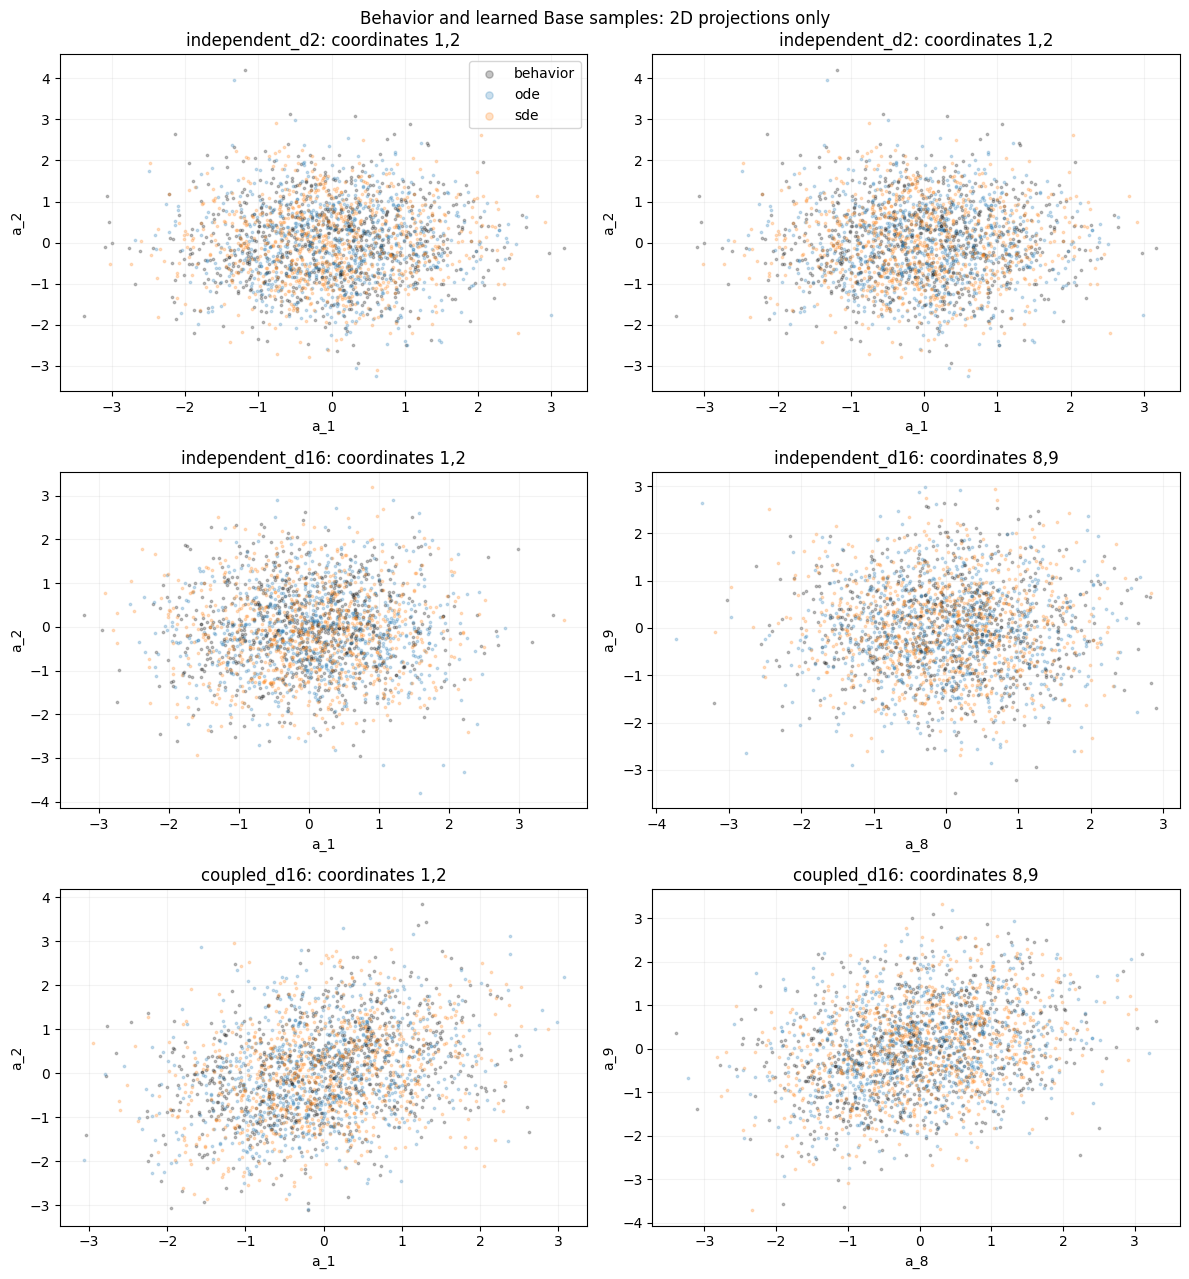

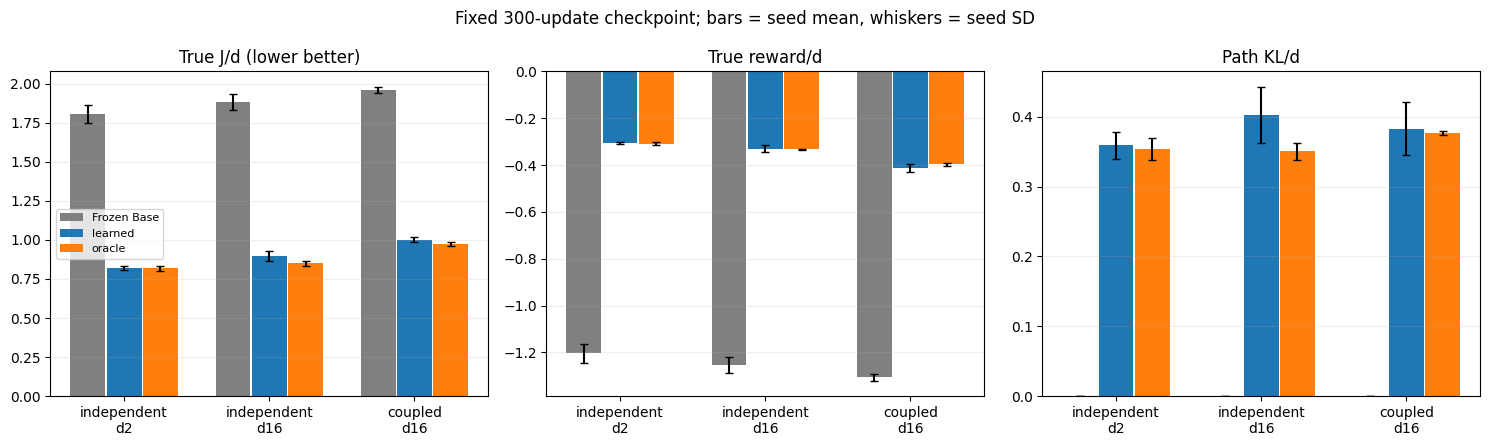

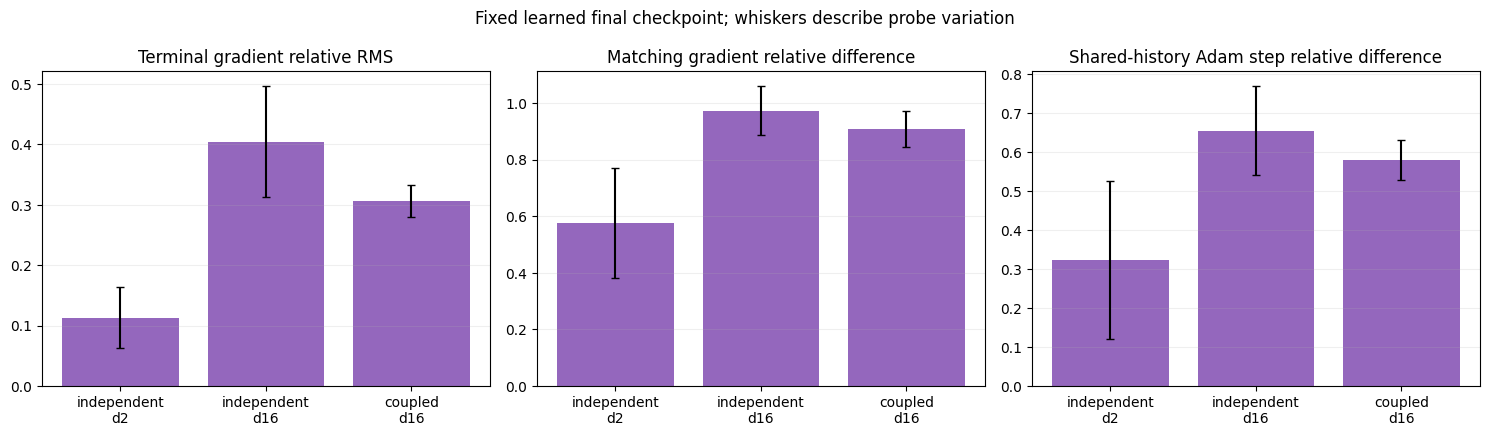

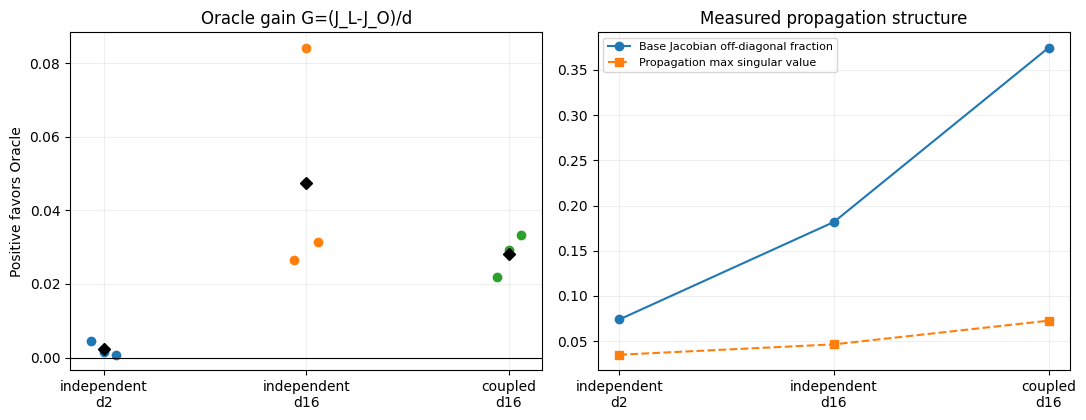

# Terminal-gradient dimension × generative coupling: executed exploratory run

Fixed tasks: ['independent_d2', 'independent_d16', 'coupled_d16']; seeds [38001, 38002, 38003]. Each task-seed uses 4096 behavior training actions, 512 noisy scalar reward labels, 5 reward models, 2500 FM updates and 300 updates per actor. The three seed numbers are new to this repository but this is exploratory.

## Direct answer

Final learned-checkpoint terminal-gradient relative RMS means: A=0.1132, B=0.4047, C=0.3063. Oracle gain G=(J_learned-J_oracle)/d means: A=0.0022446, B=0.047346, C=0.028072. Positive G favors Oracle on the same true reward-versus-KL objective.

Dimension increase coincides with a larger measured terminal-gradient error in this run.
The coupled setting has a larger measured Base Jacobian off-diagonal fraction than independent d16.
The d16 independent Oracle gain exceeds d2 in this run.
The d16 coupled Oracle gain does not exceed d16 independent in this run.
These comparisons do not isolate adjoint propagation from reward-model fit, state distribution, or pretrained Base quality. Three training seeds support an initial diagnosis, not a general dimension law.

## Every final seed and method

| task | seed | method | cost | cost_per_dim | reward_per_dim | energy_per_dim | kl_identity_max_abs |
| --- | --- | --- | --- | --- | --- | --- | --- |
| independent_d2 | 38001 | Frozen Base | 3.47731 | 1.73866 | -1.1591 | 0 | 0 |
| independent_d2 | 38001 | learned | 1.6054 | 0.802701 | -0.310733 | 0.336602 | 5.72205e-06 |
| independent_d2 | 38001 | oracle | 1.59653 | 0.798265 | -0.307324 | 0.337279 | 5.60284e-06 |
| independent_d2 | 38002 | Frozen Base | 3.69361 | 1.8468 | -1.2312 | 0 | 0 |
| independent_d2 | 38002 | learned | 1.64834 | 0.824172 | -0.300934 | 0.37277 | 6.4373e-06 |
| independent_d2 | 38002 | oracle | 1.64527 | 0.822637 | -0.30278 | 0.368466 | 8.46386e-06 |
| independent_d2 | 38003 | Frozen Base | 3.67069 | 1.83535 | -1.22356 | 0 | 0 |
| independent_d2 | 38003 | learned | 1.66216 | 0.83108 | -0.308525 | 0.368292 | 7.03335e-06 |
| independent_d2 | 38003 | oracle | 1.66064 | 0.830318 | -0.315427 | 0.357177 | 7.03335e-06 |
| independent_d16 | 38001 | Frozen Base | 29.721 | 1.85756 | -1.23838 | 0 | 0 |
| independent_d16 | 38001 | learned | 13.8554 | 0.865962 | -0.322585 | 0.382085 | 1.14441e-05 |
| independent_d16 | 38001 | oracle | 13.4311 | 0.839446 | -0.331104 | 0.342791 | 1.28746e-05 |
| independent_d16 | 38002 | Frozen Base | 29.5629 | 1.84768 | -1.23179 | 0 | 0 |
| independent_d16 | 38002 | learned | 14.8321 | 0.927005 | -0.318482 | 0.449282 | 1.43051e-05 |
| independent_d16 | 38002 | oracle | 13.4844 | 0.842774 | -0.332068 | 0.344672 | 1.04904e-05 |
| independent_d16 | 38003 | Frozen Base | 31.0449 | 1.94031 | -1.29354 | 0 | 0 |
| independent_d16 | 38003 | learned | 14.3843 | 0.899018 | -0.347558 | 0.377681 | 1.43051e-05 |
| independent_d16 | 38003 | oracle | 13.8836 | 0.867726 | -0.335889 | 0.363892 | 1.14441e-05 |
| coupled_d16 | 38001 | Frozen Base | 30.9608 | 1.93505 | -1.29003 | 0 | 0 |
| coupled_d16 | 38001 | learned | 15.8939 | 0.99337 | -0.431922 | 0.345487 | 1.43051e-05 |
| coupled_d16 | 38001 | oracle | 15.5445 | 0.971532 | -0.39564 | 0.378072 | 1.33514e-05 |
| coupled_d16 | 38002 | Frozen Base | 31.5502 | 1.97189 | -1.31459 | 0 | 0 |
| coupled_d16 | 38002 | learned | 15.8469 | 0.990432 | -0.405165 | 0.382685 | 1.23978e-05 |
| coupled_d16 | 38002 | oracle | 15.3809 | 0.961307 | -0.391598 | 0.373911 | 1.04904e-05 |
| coupled_d16 | 38003 | Frozen Base | 31.5477 | 1.97173 | -1.31449 | 0 | 0 |
| coupled_d16 | 38003 | learned | 16.2936 | 1.01835 | -0.398312 | 0.420884 | 1.04904e-05 |
| coupled_d16 | 38003 | oracle | 15.7616 | 0.985099 | -0.404147 | 0.378879 | 1.33514e-05 |

## Task means and training-seed SD

| task | method | cost_mean | cost_std | cost_per_dim_mean | cost_per_dim_std | reward_per_dim_mean | reward_per_dim_std | energy_per_dim_mean | energy_per_dim_std |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| coupled_d16 | Frozen Base | 31.3529 | 0.339593 | 1.95956 | 0.0212246 | -1.30637 | 0.0141497 | 0 | 0 |
| coupled_d16 | learned | 16.0115 | 0.245478 | 1.00072 | 0.0153424 | -0.4118 | 0.0177601 | 0.383019 | 0.0376999 |
| coupled_d16 | oracle | 15.5623 | 0.190963 | 0.972646 | 0.0119352 | -0.397128 | 0.00640581 | 0.376954 | 0.00266613 |
| independent_d16 | Frozen Base | 30.1096 | 0.813841 | 1.88185 | 0.0508651 | -1.25457 | 0.03391 | 0 | 0 |
| independent_d16 | learned | 14.3573 | 0.488904 | 0.897328 | 0.0305565 | -0.329541 | 0.0157373 | 0.403016 | 0.0401283 |
| independent_d16 | oracle | 13.5997 | 0.2473 | 0.849982 | 0.0154563 | -0.33302 | 0.00253082 | 0.350452 | 0.0116777 |
| independent_d2 | Frozen Base | 3.61387 | 0.118816 | 1.80694 | 0.0594082 | -1.20462 | 0.0396055 | 0 | 0 |
| independent_d2 | learned | 1.63864 | 0.029598 | 0.819318 | 0.014799 | -0.306731 | 0.00513976 | 0.359221 | 0.0197163 |
| independent_d2 | oracle | 1.63415 | 0.0334698 | 0.817073 | 0.0167349 | -0.308511 | 0.00640609 | 0.354307 | 0.0157907 |

## Per-seed Oracle gains and Oracle versus Frozen

| task | seed | oracle_gain_J | oracle_gain_J_per_dim | oracle_gain_over_frozen_J |
| --- | --- | --- | --- | --- |
| coupled_d16 | 38001 | 0.349404 | 0.0218378 | 15.4162 |
| coupled_d16 | 38002 | 0.465995 | 0.0291247 | 16.1693 |
| coupled_d16 | 38003 | 0.53205 | 0.0332531 | 15.7861 |
| independent_d16 | 38001 | 0.424251 | 0.0265157 | 16.2899 |
| independent_d16 | 38002 | 1.34769 | 0.0842307 | 16.0785 |
| independent_d16 | 38003 | 0.500677 | 0.0312923 | 17.1613 |
| independent_d2 | 38001 | 0.00887252 | 0.00443626 | 1.88078 |
| independent_d2 | 38002 | 0.00306962 | 0.00153481 | 2.04833 |
| independent_d2 | 38003 | 0.00152523 | 0.000762617 | 2.01006 |

Task mean and seed SD of the gains:

| task | oracle_gain_J_per_dim_mean | oracle_gain_J_per_dim_std | oracle_gain_over_frozen_J_mean | oracle_gain_over_frozen_J_std |
| --- | --- | --- | --- | --- |
| coupled_d16 | 0.0280719 | 0.00578006 | 15.7905 | 0.376532 |
| independent_d16 | 0.0473462 | 0.032032 | 16.5099 | 0.573944 |
| independent_d2 | 0.00224456 | 0.00193694 | 1.97972 | 0.0877976 |

An Oracle reward increase alone is insufficient: the cost column includes the exact finite-chain KL energy. If Oracle cannot improve Frozen on a task, Base quality or finite optimization limits are immediate constraints.

## Reward fit and propagation mechanism

| task | value_rmse_over_true_reward_std | terminal_gradient_relative_rms | q_relative_difference | step_relative_difference |
| --- | --- | --- | --- | --- |
| coupled_d16 | 0.397588 | 0.306346 | 0.90783 | 0.580438 |
| independent_d16 | 0.883652 | 0.404659 | 0.973097 | 0.655054 |
| independent_d2 | 0.130351 | 0.113227 | 0.575841 | 0.324589 |

The full diagnostics CSV also contains gradient cosines/norm ratios, zero-scale flags, raw value RMSE, and 8 separate rollout repeats at the initial and learned-final checkpoints. The adjoint-time CSV reports both absolute error and correct signal RMS at four fixed times. The shared-history virtual Adam step does not predict the entire independent training trajectory.

| task | base_jacobian_offdiag_fraction | propagator_sigma_max | propagator_sigma_min |
| --- | --- | --- | --- |
| coupled_d16 | 0.374569 | 0.0726919 | 0.0161914 |
| independent_d16 | 0.181862 | 0.0465112 | 0.0250888 |
| independent_d2 | 0.0739989 | 0.0350289 | 0.0310359 |

A singular value below one means contraction for that measured direction; no amplification threshold was imposed.

## Pretrained Base quality

| task | base_step0_fm_loss_per_dim | base_heldout_fm_loss_per_dim | ode_random_projection_w2 | sde_random_projection_w2 | ode_adjacent_corr_gap_rms | sde_adjacent_corr_gap_rms |
| --- | --- | --- | --- | --- | --- | --- |
| coupled_d16 | 2.11878 | 1.64387 | 0.064501 | 0.0766385 | 0.032939 | 0.0320641 |
| independent_d16 | 2.01598 | 1.57559 | 0.0683789 | 0.0771563 | 0.0397914 | 0.0365075 |
| independent_d2 | 1.9699 | 1.55559 | 0.0743807 | 0.0824918 | 0.0416425 | 0.0383604 |

Each seed has per-coordinate mean/variance and adjacent-correlation arrays, paired behavior/Base ODE/Base SDE samples, and inverse-transform Gaussian checks. Random-projection W2 and 2D plots are partial fit diagnostics, not full high-dimensional distribution metrics.

## Fixed training and measurement budgets

| task | seed | source | updates | training_rollouts | stochastic_velocity_calls | warmup_velocity_calls | oracle_gradient_points | clipping_count | wall_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| independent_d2 | 38001 | learned | 300 | 19200 | 1.2288e+06 | 307200 | 0 | 1 | 6.0766 |
| independent_d2 | 38001 | oracle | 300 | 19200 | 1.2288e+06 | 307200 | 19200 | 1 | 5.79938 |
| independent_d2 | 38002 | learned | 300 | 19200 | 1.2288e+06 | 307200 | 0 | 3 | 6.50607 |
| independent_d2 | 38002 | oracle | 300 | 19200 | 1.2288e+06 | 307200 | 19200 | 2 | 5.66193 |
| independent_d2 | 38003 | learned | 300 | 19200 | 1.2288e+06 | 307200 | 0 | 1 | 5.72031 |
| independent_d2 | 38003 | oracle | 300 | 19200 | 1.2288e+06 | 307200 | 19200 | 0 | 5.58561 |
| independent_d16 | 38001 | learned | 300 | 19200 | 1.2288e+06 | 307200 | 0 | 0 | 5.87317 |
| independent_d16 | 38001 | oracle | 300 | 19200 | 1.2288e+06 | 307200 | 19200 | 0 | 7.03083 |
| independent_d16 | 38002 | learned | 300 | 19200 | 1.2288e+06 | 307200 | 0 | 0 | 7.48909 |
| independent_d16 | 38002 | oracle | 300 | 19200 | 1.2288e+06 | 307200 | 19200 | 0 | 7.03808 |
| independent_d16 | 38003 | learned | 300 | 19200 | 1.2288e+06 | 307200 | 0 | 0 | 6.09735 |
| independent_d16 | 38003 | oracle | 300 | 19200 | 1.2288e+06 | 307200 | 19200 | 0 | 5.95872 |
| coupled_d16 | 38001 | learned | 300 | 19200 | 1.2288e+06 | 307200 | 0 | 0 | 5.93419 |
| coupled_d16 | 38001 | oracle | 300 | 19200 | 1.2288e+06 | 307200 | 19200 | 0 | 5.82284 |
| coupled_d16 | 38002 | learned | 300 | 19200 | 1.2288e+06 | 307200 | 0 | 0 | 7.32198 |
| coupled_d16 | 38002 | oracle | 300 | 19200 | 1.2288e+06 | 307200 | 19200 | 0 | 7.34489 |
| coupled_d16 | 38003 | learned | 300 | 19200 | 1.2288e+06 | 307200 | 0 | 0 | 6.58901 |
| coupled_d16 | 38003 | oracle | 300 | 19200 | 1.2288e+06 | 307200 | 19200 | 0 | 5.68509 |

FM loss and matching loss are divided by d. Reward and energy are both left in the same true objective J; division by d in summaries does not alter beta. The observed-data noise scale was calibrated on an independent fixed behavior sample for each task-seed before reward fitting. Learned actor updates were run with the truth API blocked.

## Limits and next question

This first round changes both reward-model input distribution and the learned Flow when rho changes. It cannot assign a larger B/C gap uniquely to the adjoint. An optional oracle-assisted equal-error diagnostic is specified in the config but disabled; no kappa intervention was run. The previous four-mode 2D negative result is retained separately.

Figures: behavior-base-projections.png, final-reward-KL-J.png, terminal-gradient-to-Adam.png, oracle-gain-and-propagation.png. All data and checkpoints reside in this unique run.


Complete run: runs/02-flow-am-dim-formal-8q5obfng


In [5]:
def make_figures(result, c, out):
    files = []
    fig, axes = plt.subplots(3, 2, figsize=(12, 13))
    for row, task in enumerate(c.tasks):
        samples = result['visual'][task.name]
        for column, pair in enumerate(((0, 1), (task.dim//2-1, task.dim//2))):
            ax = axes[row, column]
            for name, color in [('behavior', 'black'), ('ode', 'tab:blue'), ('sde', 'tab:orange')]:
                values = samples[name][:768].numpy()
                ax.scatter(values[:, pair[0]], values[:, pair[1]], s=3, alpha=.23,
                           color=color, label=name)
            ax.set_title(f'{task.name}: coordinates {pair[0]+1},{pair[1]+1}')
            ax.set_xlabel(f'a_{pair[0]+1}')
            ax.set_ylabel(f'a_{pair[1]+1}')
            ax.grid(alpha=.15)
    axes[0, 0].legend(markerscale=3)
    fig.suptitle('Behavior and learned Base samples: 2D projections only')
    fig.tight_layout()
    fig.savefig(out/'behavior-base-projections.png', dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    files.append('behavior-base-projections.png')

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    metrics = [('cost_per_dim', 'True J/d (lower better)'),
               ('reward_per_dim', 'True reward/d'),
               ('energy_per_dim', 'Path KL/d')]
    colors = {'Frozen Base': '0.5', 'learned': 'tab:blue', 'oracle': 'tab:orange'}
    for ax, (metric, title) in zip(axes, metrics):
        for offset, method in enumerate(('Frozen Base', 'learned', 'oracle')):
            subset = result['final'][result['final'].method.eq(method)]
            grouped = subset.groupby('task')[metric].agg(['mean', 'std'])
            names = [task.name for task in c.tasks]
            positions = np.arange(len(names))+(offset-1)*.25
            ax.bar(positions, grouped.loc[names, 'mean'], width=.24,
                   yerr=grouped.loc[names, 'std'], color=colors[method],
                   label=method, capsize=3)
        ax.set_xticks(range(3), [task.name.replace('_', '\n') for task in c.tasks])
        ax.set_title(title)
        ax.grid(axis='y', alpha=.2)
    axes[0].legend(fontsize=8)
    fig.suptitle('Fixed 300-update checkpoint; bars = seed mean, whiskers = seed SD')
    fig.tight_layout()
    fig.savefig(out/'final-reward-KL-J.png', dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    files.append('final-reward-KL-J.png')

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    task_names = [task.name for task in c.tasks]
    diagnostics = result['diagnostics'][result['diagnostics'].checkpoint_step.eq(c.actor_updates)]
    for ax, column, title in zip(
            axes, ('terminal_gradient_relative_rms', 'q_relative_difference',
                   'step_relative_difference'),
            ('Terminal gradient relative RMS', 'Matching gradient relative difference',
             'Shared-history Adam step relative difference')):
        grouped = diagnostics.groupby('task')[column].agg(['mean', 'std'])
        ax.bar(range(3), grouped.loc[task_names, 'mean'],
               yerr=grouped.loc[task_names, 'std'], capsize=3, color='tab:purple')
        ax.set_xticks(range(3), [name.replace('_', '\n') for name in task_names])
        ax.set_title(title)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle('Fixed learned final checkpoint; whiskers describe probe variation')
    fig.tight_layout()
    fig.savefig(out/'terminal-gradient-to-Adam.png', dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    files.append('terminal-gradient-to-Adam.png')

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    for index, task in enumerate(c.tasks):
        sample = result['gains'][result['gains'].task.eq(task.name)]
        axes[0].scatter(np.full(len(sample), index)+np.linspace(-.06, .06, len(sample)),
                        sample.oracle_gain_J_per_dim, label=task.name)
        axes[0].plot(index, sample.oracle_gain_J_per_dim.mean(), 'kD')
    axes[0].axhline(0, color='black', lw=.8)
    axes[0].set_xticks(range(3), [name.replace('_', '\n') for name in task_names])
    axes[0].set_title('Oracle gain G=(J_L-J_O)/d')
    axes[0].set_ylabel('Positive favors Oracle')
    structure = result['structure'][result['structure'].checkpoint_step.eq(0)]
    grouped = structure.groupby('task')[['base_jacobian_offdiag_fraction',
                                          'propagator_sigma_max']].mean()
    axes[1].plot(range(3), grouped.loc[task_names, 'base_jacobian_offdiag_fraction'],
                 'o-', label='Base Jacobian off-diagonal fraction')
    axes[1].plot(range(3), grouped.loc[task_names, 'propagator_sigma_max'],
                 's--', label='Propagation max singular value')
    axes[1].set_xticks(range(3), [name.replace('_', '\n') for name in task_names])
    axes[1].set_title('Measured propagation structure')
    axes[1].legend(fontsize=8)
    for ax in axes:
        ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(out/'oracle-gain-and-propagation.png', dpi=155, bbox_inches='tight')
    display(fig); plt.close(fig)
    files.append('oracle-gain-and-propagation.png')
    return files


def markdown_table(frame, columns):
    selected = frame[columns].copy()
    for column in selected.select_dtypes(include='number').columns:
        selected[column] = selected[column].map(
            lambda x: f'{x:.6g}' if pd.notna(x) else 'NA')
    return '\n'.join([
        '| '+' | '.join(columns)+' |',
        '| '+' | '.join('---' for _ in columns)+' |',
        *['| '+' | '.join(str(item) for item in row)+' |'
          for row in selected.itertuples(index=False, name=None)]
    ])


def make_report(result, c, files):
    summary = result['final'].groupby(['task', 'method'])[
        ['cost', 'cost_per_dim', 'reward_per_dim', 'energy_per_dim']].agg(['mean', 'std'])
    summary.columns = [f'{name}_{stat}' for name, stat in summary.columns]
    summary = summary.reset_index()
    gains = result['gains'].groupby('task')[['oracle_gain_J_per_dim',
                                            'oracle_gain_over_frozen_J']].agg(['mean', 'std'])
    gains.columns = [f'{name}_{stat}' for name, stat in gains.columns]
    gains = gains.reset_index()
    final_diagnostics = result['diagnostics'][
        result['diagnostics'].checkpoint_step.eq(c.actor_updates)]
    mechanism = final_diagnostics.groupby('task')[
        ['value_rmse_over_true_reward_std', 'terminal_gradient_relative_rms',
         'q_relative_difference', 'step_relative_difference']].mean().reset_index()
    structure = result['structure'][result['structure'].checkpoint_step.eq(0)].groupby('task')[
        ['base_jacobian_offdiag_fraction', 'propagator_sigma_max',
         'propagator_sigma_min']].mean().reset_index()
    base = result['quality'].groupby('task')[
        ['base_step0_fm_loss_per_dim', 'base_heldout_fm_loss_per_dim',
         'ode_random_projection_w2', 'sde_random_projection_w2',
         'ode_adjacent_corr_gap_rms', 'sde_adjacent_corr_gap_rms']].mean().reset_index()
    gap = gains.set_index('task')['oracle_gain_J_per_dim_mean']
    gradient = mechanism.set_index('task')['terminal_gradient_relative_rms']
    g_a, g_b, g_c = (float(gap[task.name]) for task in c.tasks)
    e_a, e_b, e_c = (float(gradient[task.name]) for task in c.tasks)
    lines = [
        '# Terminal-gradient dimension × generative coupling: executed exploratory run',
        '',
        f'Fixed tasks: {[task.name for task in c.tasks]}; seeds {list(c.seeds)}. '
        f'Each task-seed uses {c.behavior_train} behavior training actions, '
        f'{c.reward_train} noisy scalar reward labels, {c.ensemble_members} reward models, '
        f'{c.fm_updates} FM updates and {c.actor_updates} updates per actor. '
        'The three seed numbers are new to this repository but this is exploratory.',
        '',
        '## Direct answer', '',
        f'Final learned-checkpoint terminal-gradient relative RMS means: '
        f'A={e_a:.4g}, B={e_b:.4g}, C={e_c:.4g}. '
        f'Oracle gain G=(J_learned-J_oracle)/d means: '
        f'A={g_a:.5g}, B={g_b:.5g}, C={g_c:.5g}. '
        'Positive G favors Oracle on the same true reward-versus-KL objective.',
        '',
        ('Dimension increase coincides with a larger measured terminal-gradient error in '
         'this run.' if e_b > e_a else
         'Dimension increase does not coincide with a larger measured terminal-gradient error in this run.'),
        ('The coupled setting has a larger measured Base Jacobian off-diagonal fraction '
         'than independent d16.' if float(structure.set_index('task').loc[c.tasks[2].name,
         'base_jacobian_offdiag_fraction']) >
         float(structure.set_index('task').loc[c.tasks[1].name,
         'base_jacobian_offdiag_fraction']) else
         'The coupled setting does not have a larger measured Base Jacobian off-diagonal fraction '
         'than independent d16.'),
        ('The d16 independent Oracle gain exceeds d2 in this run.' if g_b > g_a
         else 'The d16 independent Oracle gain does not exceed d2 in this run.'),
        ('The d16 coupled Oracle gain exceeds d16 independent in this run.' if g_c > g_b
         else 'The d16 coupled Oracle gain does not exceed d16 independent in this run.'),
        'These comparisons do not isolate adjoint propagation from reward-model fit, '
        'state distribution, or pretrained Base quality. Three training seeds support '
        'an initial diagnosis, not a general dimension law.',
        '',
        '## Every final seed and method', '',
        markdown_table(result['final'], ['task', 'seed', 'method', 'cost', 'cost_per_dim',
                                          'reward_per_dim', 'energy_per_dim',
                                          'kl_identity_max_abs']), '',
        '## Task means and training-seed SD', '',
        markdown_table(summary, ['task', 'method', 'cost_mean', 'cost_std',
                                 'cost_per_dim_mean', 'cost_per_dim_std',
                                 'reward_per_dim_mean', 'reward_per_dim_std',
                                 'energy_per_dim_mean', 'energy_per_dim_std']), '',
        '## Per-seed Oracle gains and Oracle versus Frozen', '',
        markdown_table(result['gains'], ['task', 'seed', 'oracle_gain_J',
                                         'oracle_gain_J_per_dim',
                                         'oracle_gain_over_frozen_J']), '',
        'Task mean and seed SD of the gains:', '',
        markdown_table(gains, ['task', 'oracle_gain_J_per_dim_mean',
                               'oracle_gain_J_per_dim_std',
                               'oracle_gain_over_frozen_J_mean',
                               'oracle_gain_over_frozen_J_std']), '',
        'An Oracle reward increase alone is insufficient: the cost column includes '
        'the exact finite-chain KL energy. If Oracle cannot improve Frozen on a task, '
        'Base quality or finite optimization limits are immediate constraints.',
        '',
        '## Reward fit and propagation mechanism', '',
        markdown_table(mechanism, ['task', 'value_rmse_over_true_reward_std',
                                   'terminal_gradient_relative_rms',
                                   'q_relative_difference',
                                   'step_relative_difference']), '',
        'The full diagnostics CSV also contains gradient cosines/norm ratios, zero-scale '
        f'flags, raw value RMSE, and {c.diagnostic_repeats} separate rollout repeats at the initial and '
        'learned-final checkpoints. The adjoint-time CSV reports both absolute error '
        'and correct signal RMS at four fixed times. The shared-history virtual Adam '
        'step does not predict the entire independent training trajectory.', '',
        markdown_table(structure, ['task', 'base_jacobian_offdiag_fraction',
                                   'propagator_sigma_max',
                                   'propagator_sigma_min']), '',
        'A singular value below one means contraction for that measured direction; '
        'no amplification threshold was imposed.',
        '',
        '## Pretrained Base quality', '',
        markdown_table(base, ['task', 'base_step0_fm_loss_per_dim',
                              'base_heldout_fm_loss_per_dim',
                              'ode_random_projection_w2',
                              'sde_random_projection_w2',
                              'ode_adjacent_corr_gap_rms',
                              'sde_adjacent_corr_gap_rms']), '',
        'Each seed has per-coordinate mean/variance and adjacent-correlation arrays, '
        'paired behavior/Base ODE/Base SDE samples, and inverse-transform Gaussian '
        'checks. Random-projection W2 and 2D plots are partial fit diagnostics, '
        'not full high-dimensional distribution metrics.',
        '',
        '## Fixed training and measurement budgets', '',
        markdown_table(result['budgets'], ['task', 'seed', 'source', 'updates',
                                            'training_rollouts', 'stochastic_velocity_calls',
                                            'warmup_velocity_calls', 'oracle_gradient_points',
                                            'clipping_count', 'wall_seconds']), '',
        'FM loss and matching loss are divided by d. Reward and energy are both left '
        'in the same true objective J; division by d in summaries does not alter beta. '
        'The observed-data noise scale was calibrated on an independent fixed behavior '
        'sample for each task-seed before reward fitting. Learned actor updates were '
        'run with the truth API blocked.',
        '',
        '## Limits and next question', '',
        'This first round changes both reward-model input distribution and the learned '
        'Flow when rho changes. It cannot assign a larger B/C gap uniquely to the '
        'adjoint. An optional oracle-assisted equal-error diagnostic is specified in '
        'the config but disabled; no kappa intervention was run. '
        'The previous four-mode 2D negative result is retained separately.',
        '',
        'Figures: '+', '.join(files)+'. All data and checkpoints reside in this unique run.'
    ]
    return '\n'.join(lines)+'\n'


FIGURES = make_figures(RESULTS, CFG, OUT)
REPORT = make_report(RESULTS, CFG, FIGURES)
(OUT/'report.md').write_text(REPORT)
save_json(OUT/'completion.json', dict(status='complete', profile=CFG.profile,
          tasks=[task.name for task in CFG.tasks], seeds=list(CFG.seeds),
          base_runs=len(CFG.tasks)*len(CFG.seeds),
          reward_models=len(CFG.tasks)*len(CFG.seeds)*CFG.ensemble_members,
          actor_runs=2*len(CFG.tasks)*len(CFG.seeds),
          diagnostic_repetitions=len(CFG.tasks)*len(CFG.seeds)*2*CFG.diagnostic_repeats,
          figures=FIGURES, elapsed_seconds=time.monotonic()-START,
          formal_spec_sha256=CONFIG_SHA, source_sha256=SOURCE_SHA))
display(Markdown(REPORT))
print('Complete run:', OUT.relative_to(ROOT))